<a href="https://colab.research.google.com/github/Niroshini2002/pneumonia-xai-gradcam-lime/blob/main/notebooks/DenseNet121_ThreeClass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DenseNet-121 Three-class (Normal / Bacterial / Viral)

**Setup**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, random, numpy as np, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA = "/content/threeclass"
CLASSES = ["Normal", "Bacterial", "Viral"]
OUT = "/content/drive/MyDrive/pneumonia_project_threeclass"
os.makedirs(f"{OUT}/models", exist_ok=True)
os.makedirs(f"{OUT}/results", exist_ok=True)

Mounted at /content/drive
Device: cuda


**File list + patient-wise split**

In [ ]:
import os, shutil


os.environ["KAGGLE_API_TOKEN"] = "kaggle_key"


!pip install kaggle -q
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip -d /content/kermany_data

SRC = "/content/kermany_data/chest_xray"
DST = "/content/threeclass"
for cls in ["Normal", "Bacterial", "Viral"]:
    os.makedirs(f"{DST}/{cls}", exist_ok=True)

for split in ["train", "val", "test"]:
    for f in os.listdir(f"{SRC}/{split}/NORMAL"):
        shutil.copy(f"{SRC}/{split}/NORMAL/{f}", f"{DST}/Normal/{split}_{f}")
    for f in os.listdir(f"{SRC}/{split}/PNEUMONIA"):
        name = f.lower()
        if "bacteria" in name:
            shutil.copy(f"{SRC}/{split}/PNEUMONIA/{f}", f"{DST}/Bacterial/{split}_{f}")
        elif "virus" in name:
            shutil.copy(f"{SRC}/{split}/PNEUMONIA/{f}", f"{DST}/Viral/{split}_{f}")

for cls in ["Normal", "Bacterial", "Viral"]:
    print(cls, len(os.listdir(f"{DST}/{cls}")))

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/kermany_data/chest_xray/__MACOSX/._chest_xray? [y]es, [n]o, [A]ll, [N]one, [r]ename: Normal 1583
Bacterial 2780
Viral 1493


**Patient-wise Train / Val / Test Split**

In [ ]:

paths, labels, groups = [], [], []
for i, cls in enumerate(CLASSES):
    for f in os.listdir(f"{DATA}/{cls}"):
        name = re.sub(r"^(train|val|test)_", "", f)
        if name.lower().startswith("person"):
            g = name.split("_")[0]
        else:
            m = re.search(r"IM-(\d+)", name)
            g = "IM" + m.group(1) if m else name
        paths.append(f"{DATA}/{cls}/{f}"); labels.append(i); groups.append(g)

paths, labels, groups = np.array(paths), np.array(labels), np.array(groups)


sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sgkf.split(paths, labels, groups))
sgkf2 = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED)
tr, va = next(sgkf2.split(paths[trainval_idx], labels[trainval_idx], groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

for name, idx in [("Train", train_idx), ("Val", val_idx), ("Test", test_idx)]:
    counts = [int((labels[idx] == c).sum()) for c in range(3)]
    print(f"{name}: {len(idx)} | Normal {counts[0]} | Bacterial {counts[1]} | Viral {counts[2]}")

Train: 4677 | Normal 1255 | Bacterial 2208 | Viral 1214
Val: 565 | Normal 164 | Bacterial 264 | Viral 137
Test: 614 | Normal 164 | Bacterial 308 | Viral 142


**Dataset + ImageNet normalization**

In [ ]:

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class XrayDataset(Dataset):
    def __init__(self, idx, tf):
        self.paths, self.labels, self.tf = paths[idx], labels[idx], tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), int(self.labels[i])

BATCH = 32
train_loader = DataLoader(XrayDataset(train_idx, train_tf), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(XrayDataset(val_idx, eval_tf), batch_size=BATCH, num_workers=2, pin_memory=True)
test_loader  = DataLoader(XrayDataset(test_idx, eval_tf), batch_size=BATCH, num_workers=2, pin_memory=True)


cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=labels[train_idx])
cw = torch.tensor(cw, dtype=torch.float32)
print("Class weights (Normal, Bacterial, Viral):", cw)

Class weights (Normal, Bacterial, Viral): tensor([1.2422, 0.7061, 1.2842])


 **DenseNet-121 Model & Helper Functions**

In [ ]:

model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, 3)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=cw.to(DEVICE))
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

def run_epoch(loader, train, optimizer=None, freeze_bn=False):
    model.train() if train else model.eval()
    if train and freeze_bn:
        model.features.eval()      # frozen part-oda BatchNorm stats maaradhu
    total, n, P, L = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total += loss.item() * x.size(0); n += x.size(0)
            P.extend(out.argmax(1).cpu().numpy()); L.extend(y.cpu().numpy())
    return total / n, accuracy_score(L, P), f1_score(L, P, average="macro")

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
best = {"f1": 0.0}
BEST_PATH = f"{OUT}/models/densenet121_threeclass.pth"

def fit(epochs, optimizer, freeze_bn, tag):
    for ep in range(epochs):
        tl, ta, _ = run_epoch(train_loader, True, optimizer, freeze_bn)
        vl, va, vf = run_epoch(val_loader, False)
        for k, v in zip(history.keys(), [tl, vl, ta, va, vf]):
            history[k].append(v)
        saved = ""
        if vf > best["f1"]:
            best["f1"] = vf
            torch.save(model.state_dict(), BEST_PATH)
            saved = " <- best saved"
        print(f"[{tag}] Epoch {ep+1}/{epochs} | TrLoss {tl:.4f} | ValLoss {vl:.4f} | ValAcc {va:.4f} | ValF1 {vf:.4f}{saved}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 33.4MB/s]
/tmp/ipykernel_3021/3882513860.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))


**Model Training (Transfer Learning + Fine-tuning)**

In [ ]:

for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True
opt1 = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)
fit(5, opt1, freeze_bn=True, tag="Phase1-head")


for p in model.features.denseblock4.parameters():
    p.requires_grad = True
for p in model.features.norm5.parameters():
    p.requires_grad = True
opt2 = torch.optim.Adam([
    {"params": list(model.features.denseblock4.parameters()) + list(model.features.norm5.parameters()), "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4},
])
fit(8, opt2, freeze_bn=False, tag="Phase2-finetune")
print("Best Val F1:", best["f1"])

[Phase1-head] Epoch 1/5 | TrLoss 0.4598 | ValLoss 0.5361 | ValAcc 0.7752 | ValF1 0.7715
[Phase1-head] Epoch 2/5 | TrLoss 0.4444 | ValLoss 0.4879 | ValAcc 0.7858 | ValF1 0.7733
[Phase1-head] Epoch 3/5 | TrLoss 0.4414 | ValLoss 0.5020 | ValAcc 0.7929 | ValF1 0.7698
[Phase1-head] Epoch 4/5 | TrLoss 0.4453 | ValLoss 0.5430 | ValAcc 0.7805 | ValF1 0.7824 <- best saved
[Phase1-head] Epoch 5/5 | TrLoss 0.4512 | ValLoss 0.4870 | ValAcc 0.7876 | ValF1 0.7648
[Phase2-finetune] Epoch 1/8 | TrLoss 0.4405 | ValLoss 0.4841 | ValAcc 0.7947 | ValF1 0.7791
[Phase2-finetune] Epoch 2/8 | TrLoss 0.4400 | ValLoss 0.5084 | ValAcc 0.7912 | ValF1 0.7862 <- best saved
[Phase2-finetune] Epoch 3/8 | TrLoss 0.4348 | ValLoss 0.4956 | ValAcc 0.7876 | ValF1 0.7809
[Phase2-finetune] Epoch 4/8 | TrLoss 0.4300 | ValLoss 0.5128 | ValAcc 0.7805 | ValF1 0.7700
[Phase2-finetune] Epoch 5/8 | TrLoss 0.4148 | ValLoss 0.4847 | ValAcc 0.7965 | ValF1 0.7882 <- best saved
[Phase2-finetune] Epoch 6/8 | TrLoss 0.4200 | ValLoss 0.46

**Loss + accuracy curves**

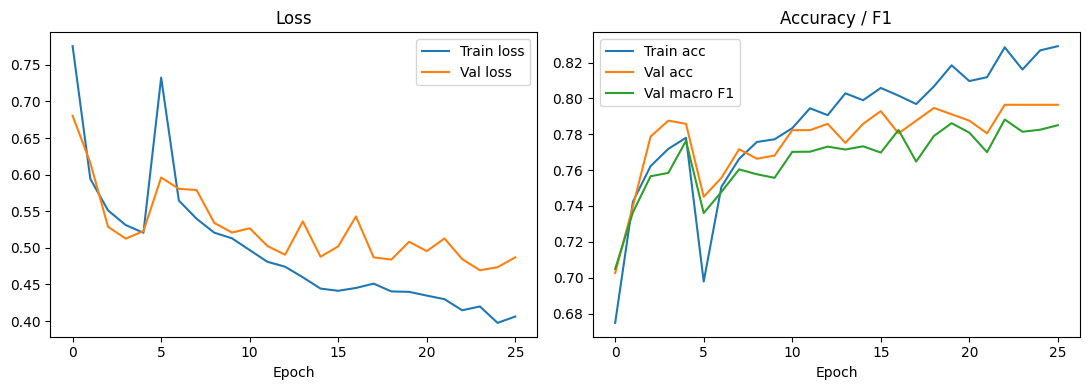

In [ ]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="Train loss"); ax[0].plot(history["val_loss"], label="Val loss")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="Train acc"); ax[1].plot(history["val_acc"], label="Val acc")
ax[1].plot(history["val_f1"], label="Val macro F1")
ax[1].set_title("Accuracy / F1"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT}/results/training_curves.png", dpi=150)
plt.show()

**Test Evaluation & Confusion Matrix**

Test Accuracy: 0.8046
Test Macro F1: 0.7932

              precision    recall  f1-score   support

      Normal     0.9398    0.9512    0.9455       164
   Bacterial     0.8459    0.8019    0.8233       308
       Viral     0.5833    0.6408    0.6107       142

    accuracy                         0.8046       614
   macro avg     0.7897    0.7980    0.7932       614
weighted avg     0.8102    0.8046    0.8068       614



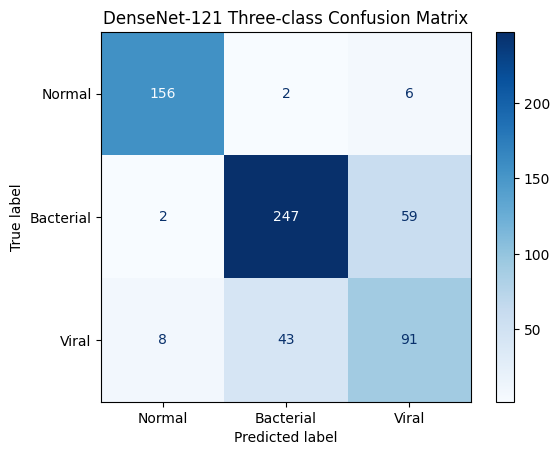

Saved in Drive: /content/drive/MyDrive/pneumonia_project_threeclass


In [ ]:

model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
model.eval()
P, L = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(DEVICE))
        P.extend(out.argmax(1).cpu().numpy()); L.extend(y.numpy())

print(f"Test Accuracy: {accuracy_score(L, P):.4f}")
print(f"Test Macro F1: {f1_score(L, P, average='macro'):.4f}\n")
print(classification_report(L, P, target_names=CLASSES, digits=4))

cm = confusion_matrix(L, P)
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(cmap="Blues", values_format="d")
plt.title("DenseNet-121 Three-class Confusion Matrix")
plt.savefig(f"{OUT}/results/confusion_matrix.png", dpi=150)
plt.show()
print("Saved in Drive:", OUT)